In [1]:
import sys
import os
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt, colors as mplcolors

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../../src'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
dims = 3

read_ids = list(range(0, 12+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_ids = read_ids

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, read_ids)
timestamps = [read_utils.get_timestamps(read_utils.get_filepath(path, file_id)) for file_id in file_ids]


# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
plot_idxs = [file_ids.index(plot_id) for plot_id in plot_ids]

# states = [ds[selection_bhl] for ds in states]

In [6]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, scale=False,
												 n_pc=dims)

In [7]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

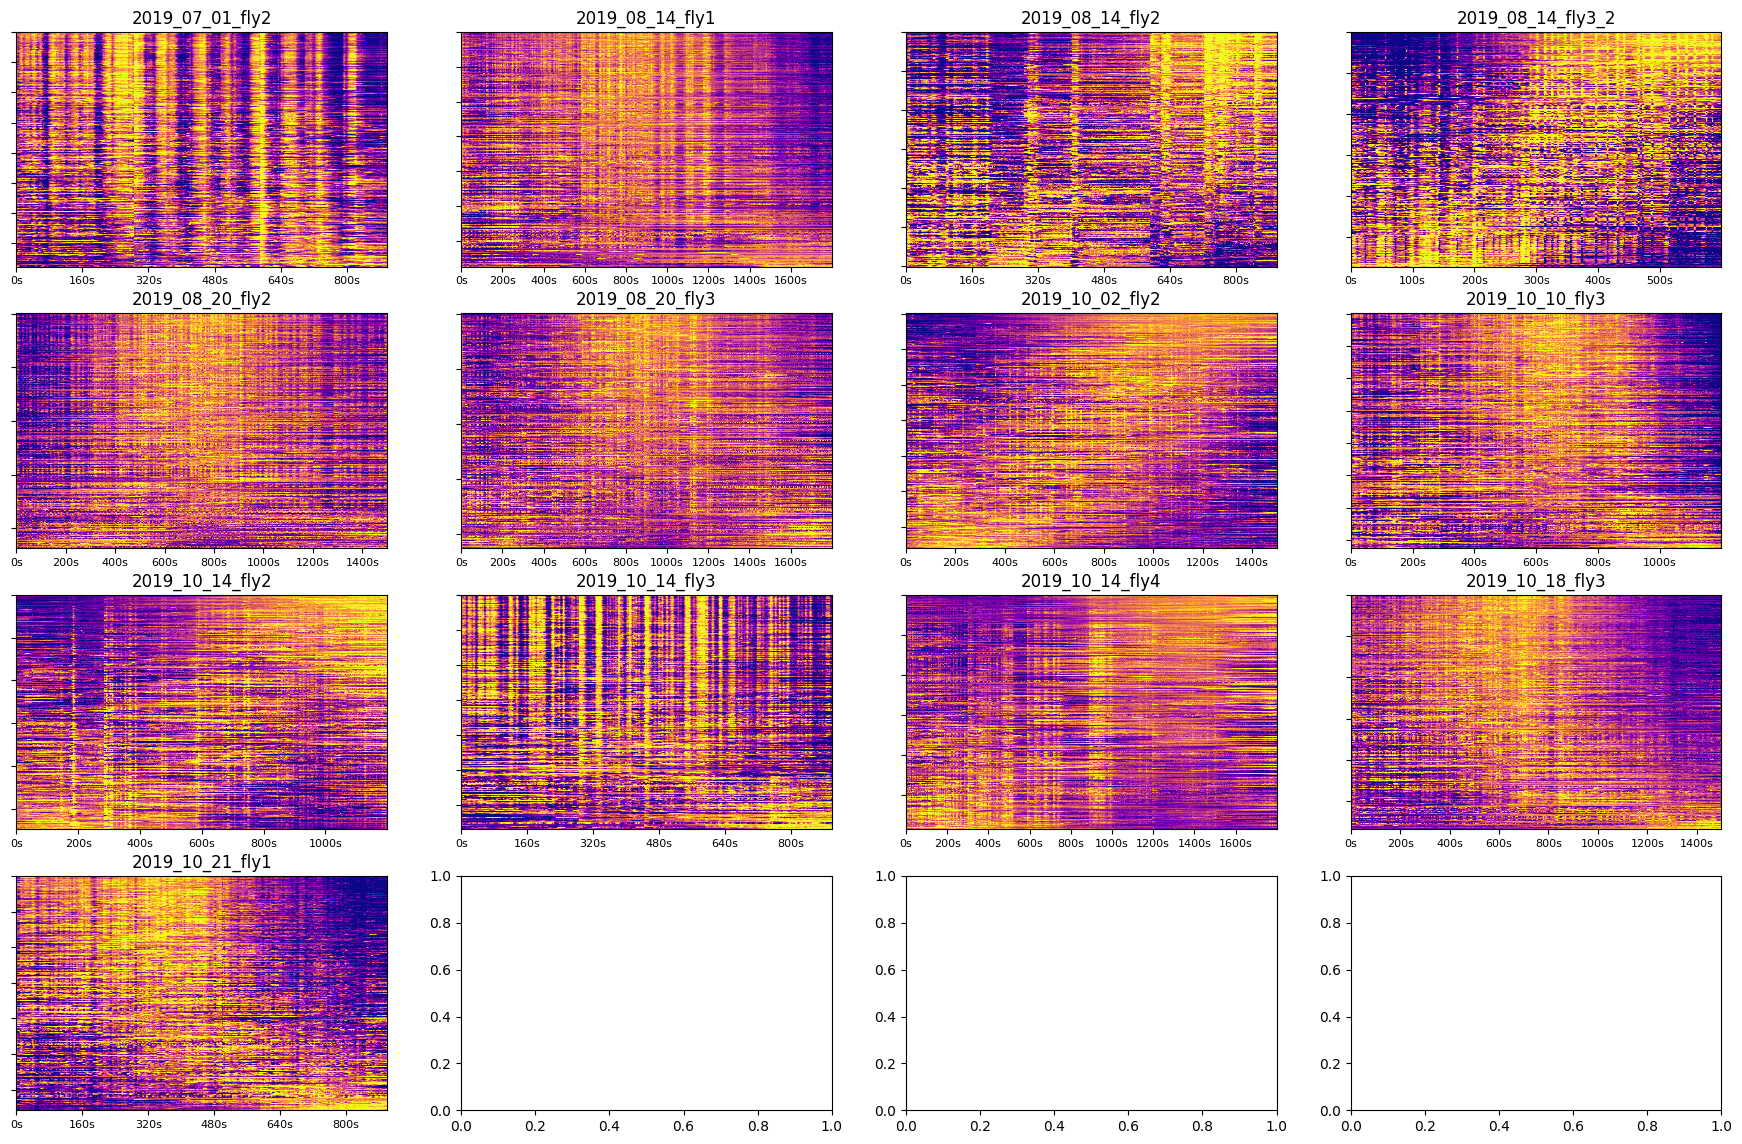

In [38]:
fig, axes = plt.subplots(4, 4, figsize=(22, 14))
for i, (filename, trace) in enumerate(zip(filenames, traces_sorted)):
	axes[i // 4, i % 4].set_title(filename)

	heatmap = np.clip(trace.values.T, -0.015, 0.015)

	axes[i // 4, i % 4].imshow(heatmap,
							   aspect='auto', interpolation='nearest',
							   cmap='plasma')

	magnitude = int(math.log10(timestamps[i][-1]))
	steps = (int(timestamps[i][-1] // 10**magnitude) * 10**(magnitude-1)) * 2
	conversion = len(timestamps[i]) / timestamps[i][-1]
	ticks = [steps * i for i in range(int(timestamps[i][-1] // steps)+1)]
	tick_positions = [tick * conversion for tick in ticks]
	axes[i // 4, i % 4].set_xticks(tick_positions)
	axes[i // 4, i % 4].set_xticklabels([f'{tick}s' for tick in ticks], fontsize=8)
	axes[i // 4, i % 4].set_yticklabels([])

plt.savefig(f'../../../out/plots/heatmaps/heatmaps', bbox_inches='tight')

In [ ]:
save_heatmaps = True

for plot_idx in plot_idxs:
	plot_utils.plot_heatmap_stack(
		traces_sorted[plot_idx],
		None,
		read_utils.get_timestamps(os.path.join(path, filenames[plot_idx])),
		'traces', 'states',
		zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False,
		save_path=f'../../../out/plots/heatmaps/{filenames[plot_idx]}' if save_heatmaps else None)